# Practical 4 - Understanding Data with Graphs

This uses the same teaching ratings dataset as Practical 2. In this one I check for duplicate professors, compare lower and upper division courses with a bar chart, and look at how age is related to the evaluation score.

Loading the libraries and the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("TeachingRatings.csv")
df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


### Q1. Duplicate cases using prof, and the average and standard deviation of age

Every row in this dataset is one course, so a professor who taught more than one course shows up more than once. The prof column is the professor id, so I use it to find the repeats.

In [2]:
print("Duplicate rows (same professor again):", df["prof"].duplicated().sum())
print("Unique professors:", df["prof"].nunique())
print("Total rows:", len(df))

Duplicate rows (same professor again): 369
Unique professors: 94
Total rows: 463


So out of 463 rows there are only 94 different professors. The other 369 rows are repeats.

First, the average and standard deviation of age using all the rows.

In [3]:
print("Using all 463 rows")
print("Mean age:", round(df["age"].mean(), 2))
print("Std dev of age:", round(df["age"].std(), 2))

Using all 463 rows
Mean age: 48.37
Std dev of age: 9.8


Now the same thing after keeping only one row for each instructor.

In [4]:
df_unique = df.drop_duplicates(subset="prof", keep="first")

print("Using one row per instructor, rows:", len(df_unique))
print("Mean age:", round(df_unique["age"].mean(), 2))
print("Std dev of age:", round(df_unique["age"].std(), 2))

Using one row per instructor, rows: 94
Mean age: 47.55
Std dev of age: 10.26


**Answer:** With all 463 rows the mean age is 48.37 and the standard deviation is 9.80. With one row per instructor (94 rows) the mean is 47.55 and the standard deviation is 10.26. The numbers are close but not the same, because in the full data a professor who taught many courses is counted many times. With one row each, every professor counts once.

### Q2. Do instructors teaching lower-division courses get higher average evaluations?

Average evaluation score for each division, shown as a bar chart.

division
lower    4.087
upper    3.953
Name: eval, dtype: float64


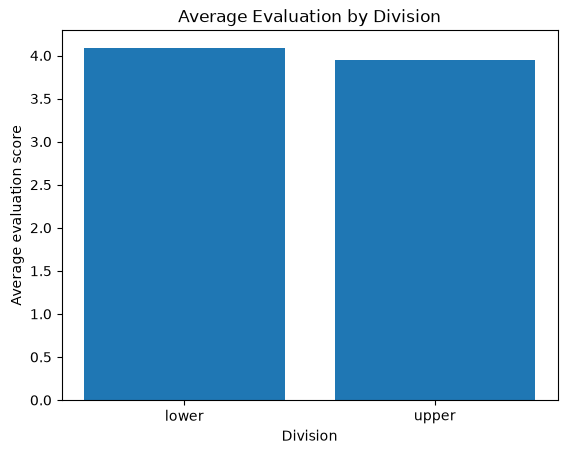

In [5]:
eval_by_division = df.groupby("division")["eval"].mean().round(3)
print(eval_by_division)

plt.bar(eval_by_division.index, eval_by_division.values)
plt.xlabel("Division")
plt.ylabel("Average evaluation score")
plt.title("Average Evaluation by Division")
plt.show()

**Answer:** Yes, a little. Lower-division courses average 4.09 and upper-division courses average 3.95. The difference is small (about 0.13), but lower-division is higher.

### Q3. Relationship between age and teaching evaluation scores

For this one I use the correlation between age and the evaluation score, and also the average evaluation for each age group.

In [6]:
print("Correlation between age and eval:", round(df["age"].corr(df["eval"]), 3))

Correlation between age and eval: -0.052


In [7]:
df["age_group"] = pd.cut(df["age"], bins=[0, 40, 50, 60, 100],
                         labels=["Under 40", "40-49", "50-59", "60+"])

age_group_table = df.groupby("age_group", observed=True)["eval"].agg(["mean", "count"]).round(3)
print(age_group_table)

            mean  count
age_group              
Under 40   4.003    113
40-49      4.059    146
50-59      3.979    145
60+        3.886     59


**Answer:** The correlation is about -0.05, which is very close to 0, so there is almost no relationship between age and evaluation score. The age groups tell the same story. Averages stay between 3.89 and 4.06, with the 40-49 group highest and the 60+ group lowest, but the differences are small.

### Q4. The same relationship for male and female instructors

Here I split the data by gender and check the correlation between age and evaluation score for each group.

In [8]:
rows = []
for g in ["female", "male"]:
    part = df[df["gender"] == g]
    rows.append([g, len(part), round(part["age"].corr(part["eval"]), 3), round(part["eval"].mean(), 3)])

gender_table = pd.DataFrame(rows, columns=["gender", "count", "corr(age, eval)", "mean eval"])
print(gender_table)

   gender  count  corr(age, eval)  mean eval
0  female    195           -0.207      3.901
1    male    268           -0.035      4.069


**Answer:** For female instructors the correlation is about -0.21, so older female instructors tend to get slightly lower evaluations. For male instructors it is about -0.04, which is basically no relationship. Both are weak, but the pattern is clearly stronger for women than for men.

### Q5. Age and evaluation score by gender and tenure

Same thing again, but now splitting into four groups: gender and tenure together.

In [9]:
rows = []
for g in ["female", "male"]:
    for t in ["yes", "no"]:
        part = df[(df["gender"] == g) & (df["tenure"] == t)]
        rows.append([g, t, len(part), round(part["age"].mean(), 1),
                     round(part["age"].corr(part["eval"]), 3), round(part["eval"].mean(), 3)])

group_table = pd.DataFrame(rows, columns=["gender", "tenured", "count", "mean age", "corr(age, eval)", "mean eval"])
print(group_table)

   gender tenured  count  mean age  corr(age, eval)  mean eval
0  female     yes    145      43.4           -0.191      3.915
1  female      no     50      49.9           -0.262      3.860
2    male     yes    216      50.8           -0.017      3.990
3    male      no     52      50.5           -0.134      4.396


**Answer:** The correlation is negative in all four groups, but it is weak in every one. It is strongest for female instructors without tenure (-0.26) and for female instructors with tenure (-0.19). It is smaller for male instructors without tenure (-0.13) and almost zero for male instructors with tenure (-0.02). One more thing in the table is that male instructors without tenure have the highest average evaluation (4.40), though that is only 52 rows.

## Conclusion

The dataset has 463 course rows but only 94 different professors, so a lot of rows are repeats. The mean age changed a little when I kept one row per professor (48.37 to 47.55). Lower-division courses got slightly higher evaluations than upper-division ones. Age and evaluation score are almost unrelated overall (correlation of about -0.05). When split by gender the link is a bit stronger for women (about -0.21) than for men (about -0.04), and splitting by tenure as well did not change that picture much.